Using device: cpu
Mounted at /content/drive


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:06<00:00, 87.9MB/s]


Epoch [1/20], Loss: 1.006736


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


NameError: name 'class_names' is not defined

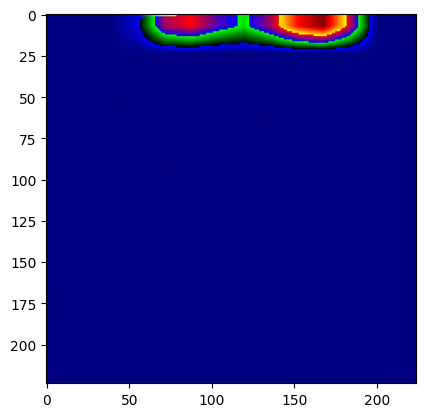

In [3]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import random
import matplotlib.pyplot as plt
from datetime import datetime
import cv2
from PIL import Image

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Define the device for computation
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Mount Google Drive to save and load the model (if using Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# Define the folder to save model checkpoints
date_str = datetime.now().strftime('%Y%m%d')
checkpoint_folder = f'/content/drive/My Drive/FYP/VGGModel/HQ2ltst_{date_str}/'
os.makedirs(checkpoint_folder, exist_ok=True)

# Data Augmentation for Training Set
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),  # VGG expects 224x224 input size
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Simple resizing for validation and test sets
transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load datasets
data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
test_data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
train_dataset = datasets.ImageFolder(data_path, transform=transform_train)
test_dataset = datasets.ImageFolder(test_data_path, transform=transform_val_test)

# Split the dataset into 80% training and 20% validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Create data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Use Pre-trained VGG-16 model and modify it for binary classification
class VGG16Modified(nn.Module):
    def __init__(self):
        super(VGG16Modified, self).__init__()
        from torchvision.models import VGG16_Weights
        self.vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
        # Replace the classifier with a custom binary classification layer
        num_ftrs = self.vgg.classifier[6].in_features
        self.vgg.classifier[6] = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.vgg(x)

# Initialize the VGG model
model = VGG16Modified().to(device)

# Define loss function and optimizer with L2 regularization (weight decay)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3)

# Grad-CAM implementation
def generate_gradcam(model, image_tensor, target_layer):
    model.eval()
    features = []
    grads = []

    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    weights = np.mean(gradient, axis=(1, 2))
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))
    cam -= np.min(cam)
    cam /= np.max(cam)
    return cam, predicted_class_idx

# Function to visualize Grad-CAM
def visualize_gradcam(image_tensor, gradcam, predicted_class_idx):
    image = image_tensor.squeeze().cpu().numpy().transpose((1, 2, 0))
    image = np.clip(image, 0, 1)

    heatmap = cv2.applyColorMap(np.uint8(255 * gradcam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    gradcam_image = np.uint8(np.float32(image) + np.float32(heatmap))
    plt.imshow(gradcam_image)
    plt.title(f"Predicted: {class_names[predicted_class_idx]}")
    plt.axis('off')
    plt.show()

# Training loop with Grad-CAM visualization after each epoch
def train_and_visualize(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20):
    target_layer = model.vgg.features[28]  # Choose a layer for Grad-CAM
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # Print training loss
        train_loss = running_loss / len(train_loader)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {train_loss:.6f}")

        # Visualize Grad-CAM on a few training images after each epoch
        img_idx = 0  # Index of the image to visualize from the batch
        image_tensor = inputs[img_idx].unsqueeze(0)

        gradcam, predicted_class_idx = generate_gradcam(model, image_tensor, target_layer)
        visualize_gradcam(image_tensor, gradcam, predicted_class_idx)

        # Validate the model
        val_acc = validate(model, val_loader, criterion)
        scheduler.step(val_acc)

# Add a validation function to compute accuracy
def validate(model, val_loader, criterion):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Validation Accuracy: {accuracy:.2f}%")
    return accuracy

# Start training and visualizing Grad-CAM
train_and_visualize(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20)
